<a href="https://colab.research.google.com/github/tachom-a11/111111/blob/main/colab/alpp_local_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Local Operations with Convolution<br>畳み込みによる局所演算

Information an image provides is represented by a combination of **local features** (fragmented shapes, patterns, and color schemes). **Convolution** is the fundamental operation for computing the amount of local features in an image.

画像がもつ情報は，局所的な特徴（断片的な形状，模様，配色）の組合せによって表されています．**畳み込み（convolution）** は，画像の**局所特徴（local features）** の量を算出する基本的な演算です．

[[Fidler+,CVPR08]](https://doi.org/10.1109/CVPR.2008.4587409)
[[Lee+, ICML09]](https://doi.org/10.1145/1553374.1553453)
<div>
<img src="https://d3i71xaburhd42.cloudfront.net/c09c802d6eb88ef9e29788df47247c9a329eac7c/3-Figure1-1.png" width="400"/>
<img src="https://www.researchgate.net/profile/Saad-Albawi/publication/319253577/figure/fig1/AS:615410118455298@1523736614895/Learned-features-from-a-Convolutional-Neural-Network.png" width="300"/>
</div>


## First, let's try local operations on a small gray-scale image.<br>まずは小さな濃淡画像で試します．

In [2]:
#@title Loads MNIST, the handwritten digit dataset.<br>手書き数字データセットMNISTを読み込みます．
#For simplicity, use the files provided in `sample_data` folder in Google Colaboratory. 簡単のため，colabにsample_dataフォルダに用意されているファイルを使います．
import pandas as pd
mnist = pd.read_csv('/content/sample_data/mnist_test.csv', header=None)

lbl = mnist.iloc[:,0].to_numpy()
imgs = mnist.drop(columns=0).to_numpy().reshape(-1,28,28)
print("(#images, height, width) =", imgs.shape)

(#images, height, width) = (10000, 28, 28)


In [3]:
i = 1234

Showing an image of digit 8 in shape (28, 28)


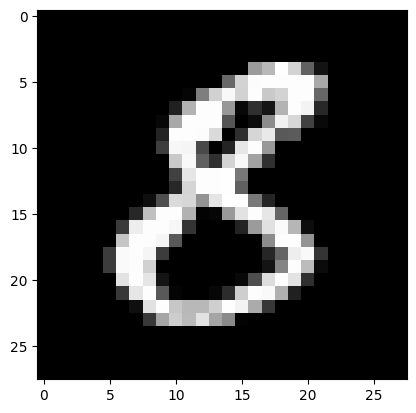

In [4]:
#@title Displays the i-th handwritten digit image.<br>i 番目の手書き数字画像を表示します．
img = imgs[i]
print("Showing an image of digit", lbl[i], "in shape", img.shape)

import matplotlib.pyplot as plt
plt.imshow(img, cmap='gray')
plt.show()

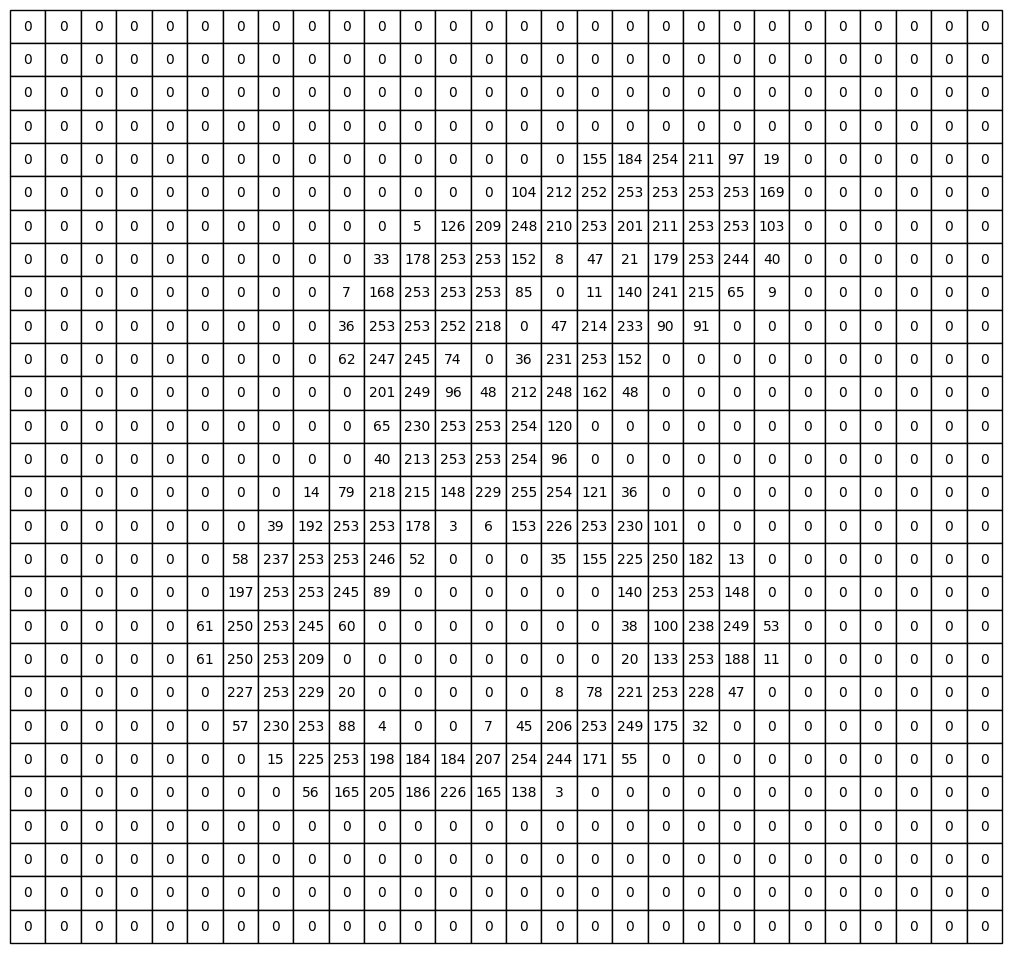

In [5]:
#@title An image is a collection of pixel values.<br>画像は数値（画素値）の集まりです．
import numpy as np
import matplotlib.pyplot as plt
plt.axis('off')
plt.table(np.round(img,1), cellLoc='center', loc='center').scale(2,2)
plt.show()

### Sets the convolution kernel.<br>畳み込み（convolution）のカーネル（kernel）を設定します．
<div>
<img src="https://upload.wikimedia.org/wikipedia/commons/a/a5/Convolutional_Neural_Network_NeuralNetworkFilter.gif" width="400" />
</div>

In [6]:
kernel = [[ -1,  0,  1],
          [ -2,  0,  2],
          [ -1,  0,  1]]

In [7]:
#@title Set the `kernel` in a convolution layer `conv` by PyTorch.<br>PyTorchの畳み込み層 `conv` にカーネルを設定します．
import torch
ker = torch.tensor(kernel).unsqueeze(0).unsqueeze(0)

#Conv2d(in_channels, out_channels, kernel_size, options)
conv = torch.nn.Conv2d(1, 1, 3, bias=False, padding=1)
conv.weight = torch.nn.Parameter(ker.float())
#conv.bias = torch.nn.Parameter(torch.tensor([1000]).float())

print("(out_channels, in_channels, kernel height, kernel width) =", conv.weight.shape)
print("\"conv\" made by torch.nn.Conv2d:", conv.weight)

(out_channels, in_channels, kernel height, kernel width) = torch.Size([1, 1, 3, 3])
"conv" made by torch.nn.Conv2d: Parameter containing:
tensor([[[[-1.,  0.,  1.],
          [-2.,  0.,  2.],
          [-1.,  0.,  1.]]]], requires_grad=True)


Input:  <class 'torch.Tensor'> torch.Size([1, 1, 28, 28])
Output: <class 'torch.Tensor'> torch.Size([1, 1, 28, 28])


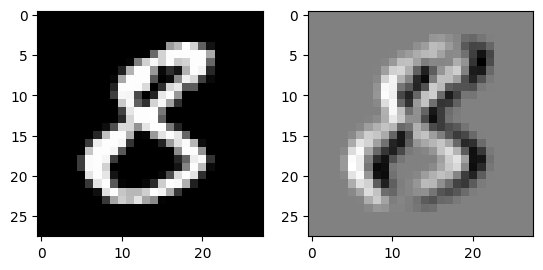

In [8]:
#@title Executes the convolution.<br>畳み込みを実行します．out_img = conv(in_img)
in_img = torch.tensor(img).unsqueeze(0).unsqueeze(0).float()
out_img = conv(in_img)

# (n, channels, height, width)
print("Input: ", type(in_img), in_img.shape)
print("Output:", type(out_img), out_img.shape)

plt.subplot(1,2,1)
plt.imshow(in_img[0,0].detach(), cmap='gray')

plt.subplot(1,2,2)
plt.imshow(out_img[0,0].detach(), cmap='gray')
plt.show()

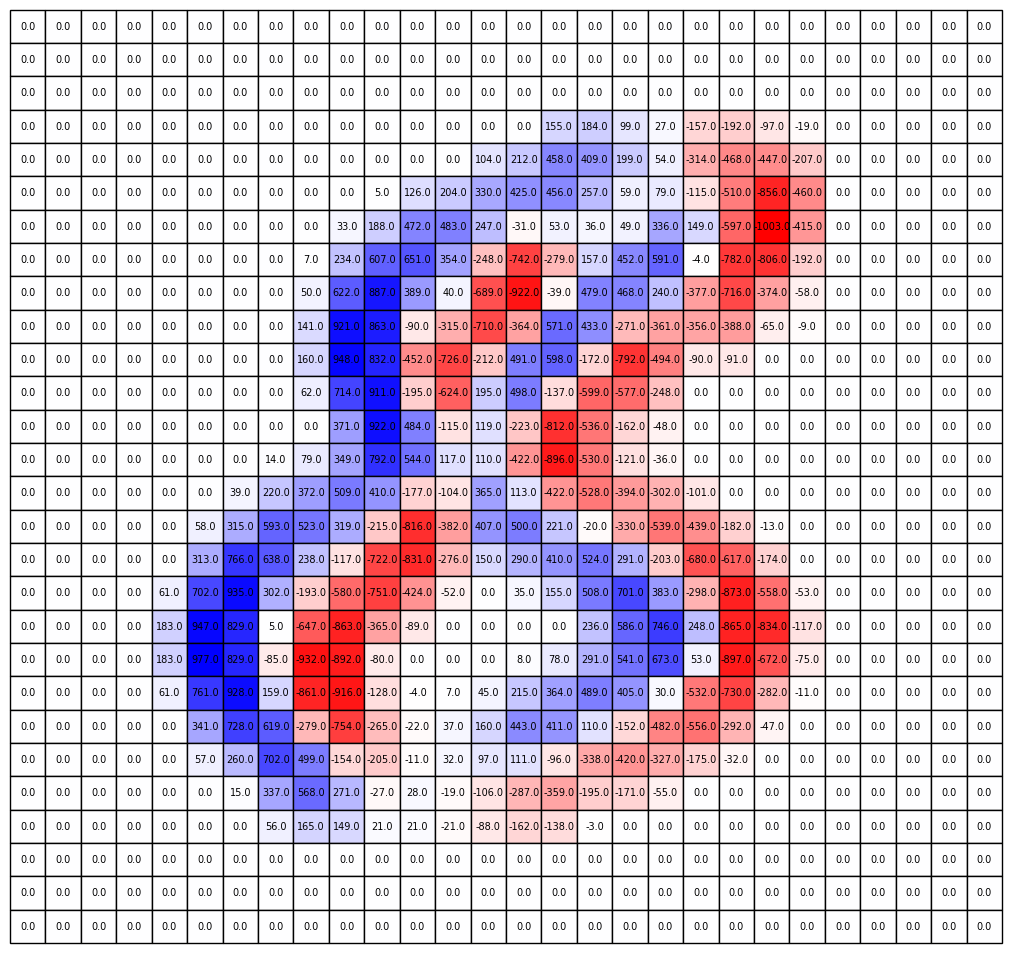

In [9]:
#@title Observe the result.<br>出力を観察しましょう．
from matplotlib.colors import TwoSlopeNorm as tsn

fmap = out_img[0,0].detach().numpy()
norm = tsn(vmin=np.minimum(fmap.min(),-1e-6), vcenter=0, vmax=np.maximum(fmap.max(),1e-3))

plt.axis('off')
tbl = plt.table(np.round(fmap,0), cellLoc='center', loc='center',
                cellColours=plt.get_cmap('bwr_r')(norm(fmap)))
tbl.scale(2,2)
tbl.auto_set_font_size(False)
tbl.set_fontsize(7)
plt.show()

## Next, try on a color image.<br>次は，カラー画像で試します．

In [ ]:
uri = "https://raw.githubusercontent.com/tsakailab/alpp/refs/heads/main/data/330px-RYB_Color_wheel.png"
#uri = "https://raw.githubusercontent.com/tsakailab/alpp/refs/heads/main/data/peppers.png"
#uri = "https://otamatone.jp/cms/wp-content/uploads/2019/09/190421_otamatone71638-300x300.jpg"

(height, width, channels) = (128, 170, 3)


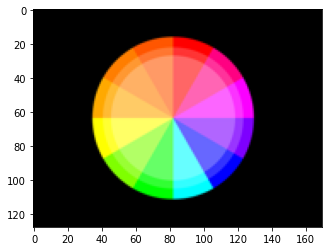

In [ ]:
#@title Downloads and displays an image.<br>画像をダウンロードして表示します．
import imageio
cimg = imageio.imread(uri)

# resize
import numpy as np
from PIL import Image
cimg = np.array(Image.fromarray(cimg).resize((cimg.shape[1] * 128 // cimg.shape[0], 128)))

print("(height, width, channels) =", cimg.shape)
import matplotlib.pyplot as plt
plt.imshow(cimg)
plt.show()

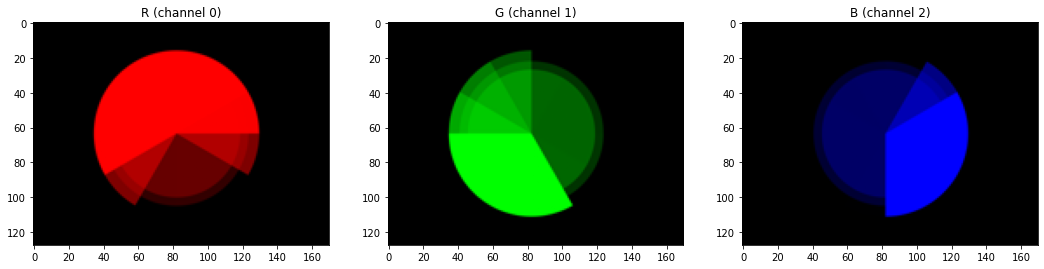

In [ ]:
#@title A color image is represented as a collection of pixel values (R,G,B).<br>カラー画像は画素値 (R,G,B) の集まりで表されています．
import numpy as np
from matplotlib.colors import LinearSegmentedColormap as lsc

plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.title("R (channel 0)")
plt.imshow(cimg[:,:,0], cmap=lsc.from_list('kr', [(0,0,0), (1,0,0)], N=255))

plt.subplot(1,3,2)
plt.title("G (channel 1)")
plt.imshow(cimg[:,:,1], cmap=lsc.from_list('kg', [(0,0,0), (0,1,0)], N=255))

plt.subplot(1,3,3)
plt.title("B (channel 2)")
plt.imshow(cimg[:,:,2], cmap=lsc.from_list('kb', [(0,0,0), (0,0,1)], N=255))

plt.show()

### Sets the convolution kernel for each color channel.<br>畳み込み（convolution）のカーネル（kernel）を設定します．

Prepare `kernel_ch0`, `kernel_ch1`, and `kernel_ch2` for R, G, and B, respectively.

R, G, B それぞれに `kernel_ch0`, `kernel_ch1`, `kernel_ch2` を用意します．
<div>
<img src="https://upload.wikimedia.org/wikipedia/commons/9/95/Convolutional_Neural_Network_with_Color_Image_Filter.gif" width="400"/>
</div>

In [ ]:
kernel_ch0 = [[ -1, -2, -1],
              [  0,  0,  0],
              [  1,  2,  1]]

kernel_ch1 = [[  0,  0,  0],
              [  0,  0,  0],
              [  0,  0,  0]]

kernel_ch2 = [[  0,  0,  0],
              [  0,  0,  0],
              [  0,  0,  0]]

In [ ]:
#@title PyTorchの畳み込み層にカーネルを設定します．
import torch
ker = torch.tensor([kernel_ch0, kernel_ch1, kernel_ch2]).unsqueeze(0)

#Conv2d(in_channels, out_channels, kernel_size, options)
conv = torch.nn.Conv2d(3, 1, 3, bias=False, padding=1)
conv.weight = torch.nn.Parameter(ker.float())
print("(out_channels, in_channels, kernel height, kernel width) =", conv.weight.shape)
print("\"conv\" made by torch.nn.Conv2d:", conv.weight)

(out_channels, in_channels, kernel height, kernel width) = torch.Size([1, 3, 3, 3])
"conv" made by torch.nn.Conv2d: Parameter containing:
tensor([[[[-1., -2., -1.],
          [ 0.,  0.,  0.],
          [ 1.,  2.,  1.]],

         [[ 0.,  0.,  0.],
          [ 0.,  0.,  0.],
          [ 0.,  0.,  0.]],

         [[ 0.,  0.,  0.],
          [ 0.,  0.,  0.],
          [ 0.,  0.,  0.]]]], requires_grad=True)


Input:  <class 'torch.Tensor'> torch.Size([1, 3, 128, 170])
Output: <class 'torch.Tensor'> torch.Size([1, 1, 128, 170])


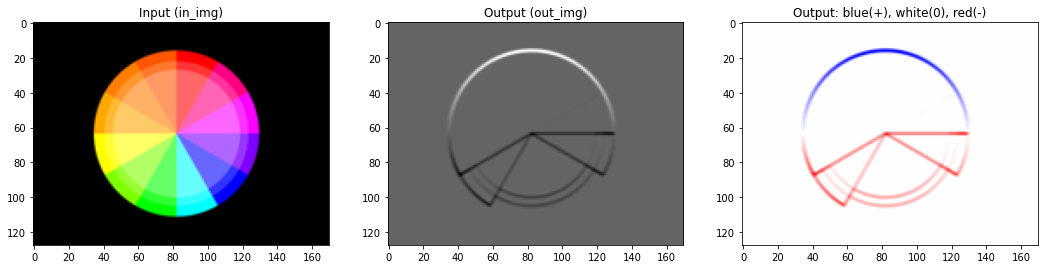

In [ ]:
#@title Executes the convolution.<br>畳み込みを実行します．out_img = conv(in_img)
in_img = torch.tensor(cimg).permute(2,0,1).unsqueeze(0).float()
out_img = conv(in_img)

# (n, channels, height, width)
print("Input: ", type(in_img), in_img.shape)
print("Output:", type(out_img), out_img.shape)

plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.title("Input (in_img)")
plt.imshow(in_img[0].detach().permute(1,2,0).to(torch.int))

fmap = out_img[0,0].detach().numpy()
plt.subplot(1,3,2)
plt.title("Output (out_img)")
plt.imshow(fmap, cmap='gray')

from matplotlib.colors import TwoSlopeNorm as tsn
norm = tsn(vmin=np.minimum(fmap.min(),-1e-3), vcenter=0, vmax=np.maximum(fmap.max(),1e-3))
plt.subplot(1,3,3)
plt.title("Output: blue(+), white(0), red(-)")
plt.imshow(fmap, cmap='bwr_r', norm=norm)

plt.show()

# Exercises<br>演習課題
- Rewrite the kernel values for color images and observe the results ([ref.](https://setosa.io/ev/image-kernels/)). What is the kernel to output the result of the following operation?
    - measure brightness
    - blur
    - express the convexity/concavity of brightness as a positive/negative amount
    - measure the intensity of yellow

- カラー画像に対する kernel の数値を書き換えて結果を観察してください
[（参考）](https://setosa.io/ev/image-kernels/)．入力画像に対して以下のような局所演算の結果を出力するための kernel は？
    - 輝度を測る
    - ぼかす
    - 輝度の凹凸を正負の量で表す
    - 黄色の強さを測る


# Recap<br>要点

Did you understand that the convolution operation produces an output image that represents the location and amount of local features where a pattern similar to the kernel is found? The image representing the distribution of local features is called a **feature map**.

By preparing a number of kernels, feature maps can be created for various local features such as edges, convex/concave fragments, color combinations, etc. A feature map can be created from any number of feature maps, as in the case of outputting a feature map from a three-channel color image.


畳み込み演算によって，カーネルに類似した模様が見つかる場所と量（局所特徴量）を表す出力画像が得られることを理解できたでしょうか．このように局所特徴量の分布を表す画像を**特徴マップ（feature map）** といいます．

カーネルを何種類も用意すれば，エッジや凹凸の断片，色の組合せなど，様々な局所特徴について特徴マップを作成できます．３枚の入力で表せるカラー画像から特徴マップを出力するときと同様に，複数の特徴マップからひとつの特徴マップを作ることもできます．

<!--
様々な局所特徴量の分布を表す複数の特徴マップに対する畳み込み演算は，局所特徴の典型的な組合せを探すことに相当します．出力の特徴マップは，典型的な局所特徴の組合せが見つかる場所と量を表しています．

畳み込み演算をする**畳み込み層（convolutional layer）**は，複数の特徴マップから複数の特徴マップを作成します．入力（出力）の特徴マップは，入力（出力）チャンネル（input/output channels）とも呼ばれます．

畳み込み層を何段ももつ**畳み込みニューラルネットワーク（convolutional neural network; CNN）**は，典型的な局所特徴の組合せ，その典型的な組合せの組合せ，さらにその組合せ・・を探す機構です．畳み込み層の間には適宜，**活性化層（activation layer）**や**プーリング層（pooling layer）**などが入ります．

活性化層は，特徴量を強調または選び出す処理により，典型的な局所特徴を見つけやすくします．プーリング層は特徴マップをぼかしてサイズを縮小します．縮小すると，局所特徴を広目に探せるようになるからです．

こららの層で構成された**特徴抽出器（feature extractor）**によって，入力画像がもつ特徴を定量化できます．**全結合層（fully connected (fc) layers）**は，特徴抽出器の出力から目的の量を算出します．物体認識の場合，全結合層は，想定している各物体が存在する確率を算出する**識別器（classifier）**の役割を担います．

![](https://www.researchgate.net/publication/329790469/figure/fig2/AS:705721712787456@1545268576139/Simplified-illustration-of-the-AlexNet-architecture.ppm)
![](https://upload.wikimedia.org/wikipedia/commons/6/63/Typical_cnn.png)

-->